In [1]:
from astroNN.datasets import load_galaxy10
from tensorflow.keras import utils
import numpy as np

# To load images and labels (will download automatically at the first time)
# First time downloading location will be ~/.astroNN/datasets/
images, labels = load_galaxy10()

# To convert the labels to categorical 10 classes
#labels = utils.to_categorical(labels, 10)

# To convert to desirable type
labels = labels.astype(np.float32)
images = images.astype(np.float32)

/Users/mariepilskog/.astroNN/datasets/Galaxy10_DECals.h5 was found!


In [2]:
from astroNN.datasets.galaxy10 import galaxy10cls_lookup
galaxy10cls_lookup(7)

'Unbarred Loose Spiral'

In [3]:
# Split into train and test
import numpy as np
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(np.arange(labels.shape[0]), test_size=0.2)
train_images, train_labels, test_images, test_labels = images[train_idx], labels[train_idx], images[test_idx], labels[test_idx]

In [4]:
print(labels)

[0. 0. 0. ... 9. 9. 9.]


In [5]:
import numpy as np

def gini(y, classes):
    """Eq. (7.7): G = 1 - sum_k p_k^2."""
    p = np.array([np.mean(y == c) for c in classes])
    return 1.0 - np.sum(p**2)

def entropy(y, classes):
    """Eq. (7.8), with 0 log 0 = 0."""
    p = np.array([np.mean(y == c) for c in classes])
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def mse_impurity(y):
    """Eq. (7.12)."""
    return np.mean((y - y.mean())**2) if len(y) else 0.0

In [18]:
class Node:
    __slots__ = ("feature", "threshold", "left", "right", "value", "n")

    def __init__(self, value=None, n=0):
        self.feature = self.threshold = self.left = self.right = None
        self.value, self.n = value, n


class DecisionTree:
    """CART for regression and classification.

    task       : "classification" or "regression"
    criterion  : "gini" or "entropy" (classification only)
    max_features: if set, only m random features are tried at each split
                  (more only if none of them can split the node) -- this is
                  what turns bagging into a random forest.
    Zero-gain splits are allowed (XOR needs one); a node becomes a leaf only
    when no admissible split exists or a stopping rule fires.
    """

    def __init__(self, task="classification", criterion="gini", max_depth=None,
                 min_samples_split=2, min_samples_leaf=1, max_features=None,
                 rng=None):
        self.task, self.criterion = task, criterion
        self.max_depth = np.inf if max_depth is None else max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng() if rng is None else rng

    def _impurity(self, y):
        if self.task == "regression":
            return mse_impurity(y)
        return (gini(y, self.classes_) if self.criterion == "gini"
                else entropy(y, self.classes_))

    def _leaf_value(self, y):
        if self.task == "regression":
            return y.mean()                              # the optimal constant
        counts = [np.sum(y == c) for c in self.classes_]
        return self.classes_[int(np.argmax(counts))]     # majority vote

    def _best_split(self, X, y):
        n, p = X.shape
        features = np.arange(p)
        if self.max_features is not None and self.max_features < p:
            features = self.rng.permutation(p)           # random forest: a fresh random order
        parent = self._impurity(y)
        best_gain, best_j, best_t = -np.inf, None, None  # any admissible split beats "none"
        for rank, j in enumerate(features):
            if (self.max_features is not None and rank >= self.max_features
                    and best_j is not None):
                break                                    # m features tried, one of them works
            xs = X[:, j]
            uniq = np.unique(xs)
            if len(uniq) < 2:
                continue
            for t in (uniq[:-1] + uniq[1:]) / 2.0:       # candidate midpoints
                mask = xs <= t
                nl, nr = mask.sum(), n - mask.sum()
                if nl < self.min_samples_leaf or nr < self.min_samples_leaf:
                    continue
                child = (nl / n) * self._impurity(y[mask]) + (nr / n) * self._impurity(y[~mask])
                gain = parent - child                    # Eq. (7.10)
                if gain > best_gain + 1e-12:
                    best_gain, best_j, best_t = gain, j, t
        return best_gain, best_j, best_t

    def _build(self, X, y, depth):
        node = Node(self._leaf_value(y), len(y))
        if (depth >= self.max_depth or len(y) < self.min_samples_split
                or len(np.unique(y)) == 1):
            return node
        gain, j, t = self._best_split(X, y)
        if j is None:                                    # no admissible split (gain 0 is fine)
            return node
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._build(X[mask], y[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        if self.task == "classification":
            self.classes_ = np.unique(y)
        self.root_ = self._build(X, y, 0)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for x in X:
            node = self.root_
            while node.feature is not None:              # walk to a leaf
                node = node.left if x[node.feature] <= node.threshold else node.right
            out.append(node.value)
        return np.array(out)

    def depth(self):
        def d(node):
            return 0 if node.feature is None else 1 + max(d(node.left), d(node.right))
        return d(self.root_)

    def n_leaves(self):
        def c(node):
            return 1 if node.feature is None else c(node.left) + c(node.right)
        return c(self.root_)

In [19]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y_xor = np.array([0, 1, 1, 0])
for crit in ["gini", "entropy"]:
    t = DecisionTree("classification", crit).fit(X_xor, y_xor)
    print(f"XOR, {crit:8s}: depth {t.depth()}, leaves {t.n_leaves()}, "
          f"training accuracy {np.mean(t.predict(X_xor) == y_xor):.2f}")

XOR, gini    : depth 2, leaves 4, training accuracy 1.00
XOR, entropy : depth 2, leaves 4, training accuracy 1.00


In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, display

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
SEED = 2026
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [21]:
def toy_points():
    """Ten points in the plane, two classes, chosen so that CART needs three
    splits to separate them and so that the arithmetic can be done by hand."""
    X = np.array([[1.0, 1.0], [2.0, 2.0], [3.0, 2.0], [1.5, 4.0], [5.0, 1.0],      # class 0
                  [4.0, 4.0], [5.0, 3.0], [6.0, 5.0], [1.0, 5.0], [5.5, 4.5]])     # class 1
    y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
    return X, y


def cart_scan(X, y, criterion="gini", classes=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9)):
    """Score every candidate threshold of every feature: Eqs. (7.9)-(7.10).

    Returns a list of (feature, threshold, n_left, n_right, child_impurity, gain).
    """
    imp = gini if criterion == "gini" else entropy
    parent = imp(y, classes)
    rows = []
    for j in range(X.shape[1]):
        uniq = np.unique(X[:, j])
        for t in (uniq[:-1] + uniq[1:]) / 2.0:         # midpoints between sorted values
            mask = X[:, j] <= t
            nl, nr = mask.sum(), (~mask).sum()
            child = nl / len(y) * imp(y[mask], classes) + nr / len(y) * imp(y[~mask], classes)
            rows.append((j, t, nl, nr, child, parent - child))
    return parent, rows


def print_scan(X, y, criterion):
    parent, rows = cart_scan(X, y, criterion)
    print(f"\n{criterion}: parent impurity = {parent:.4f}")
    print(" feature  threshold  n_left n_right  C(k,t)   gain")
    for j, t, nl, nr, child, gain in rows:
        print(f"   x{j+1}      {t:5.2f}      {nl:2d}     {nr:2d}    {child:.4f}  {gain:.4f}")
    best = max(rows, key=lambda r: r[-1])
    print(f" best: x{best[0]+1} <= {best[1]:.2f}, gain {best[-1]:.4f}")
    return parent, rows, best

In [22]:
def draw_splits(node, ax, xlim, ylim, counter=None):
    """Draw the axis-aligned splits of a fitted tree, each inside the box of
    its node, numbered in the order in which CART makes them (depth first)."""
    if node.feature is None:
        return
    counter = [0] if counter is None else counter
    counter[0] += 1
    col = [GREEN, YELLOW, GREY, BLUE][min(counter[0] - 1, 3)]
    lab = f"split {counter[0]}: $x_{node.feature + 1}\\leq{node.threshold:g}$"
    if node.feature == 0:
        ax.plot([node.threshold] * 2, ylim, color=col, lw=2, zorder=2, label=lab)
        draw_splits(node.left, ax, (xlim[0], node.threshold), ylim, counter)
        draw_splits(node.right, ax, (node.threshold, xlim[1]), ylim, counter)
    else:
        ax.plot(xlim, [node.threshold] * 2, color=col, lw=2, zorder=2, label=lab)
        draw_splits(node.left, ax, xlim, (ylim[0], node.threshold), counter)
        draw_splits(node.right, ax, xlim, (node.threshold, ylim[1]), counter)


def fig_cart_scan(fname="week46_cart_scan.pdf"):
    X, y = train_images, train_labels
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.6))

    # the points and the first split
    for c, m, col in [(0, "o", BLUE), (1, "s", RED)]:
        ax[0].scatter(X[y == c, 0], X[y == c, 1], marker=m, s=70, color=col,
                      edgecolor="k", label=f"class {c}", zorder=3)
    for i, (x1, x2) in enumerate(X):
        ax[0].annotate(str(i + 1), (x1, x2), textcoords="offset points", xytext=(6, 4), fontsize=8)
    tree = DecisionTree("classification", "gini").fit(X, y)
    draw_splits(tree.root_, ax[0], (0.5, 6.5), (0.5, 5.6))
    ax[0].set_xlim(0.5, 6.5)
    ax[0].set_ylim(0.5, 6.6)
    ax[0].set_xlabel("$x_1$")
    ax[0].set_ylabel("$x_2$")
    ax[0].set_title("Ten points and the three CART splits")
    ax[0].legend(frameon=False, fontsize=7.5, loc="upper center", ncol=3, columnspacing=0.8)

    # gain against threshold for both features, both criteria
    for k, (crit, col) in enumerate([("gini", BLUE), ("entropy", RED)]):
        parent, rows = cart_scan(X, y, crit)
        for j, ls in [(0, "-"), (1, "--")]:
            r = [row for row in rows if row[0] == j]
            ts = [row[1] for row in r]
            gs = [row[-1] for row in r]
            ax[1 + k].plot(ts, gs, ls, marker="o", color=col, label=f"$x_{j+1}\\leq t$")
        best = max(rows, key=lambda r: r[-1])
        ax[1 + k].scatter([best[1]], [best[-1]], s=160, facecolor="none", edgecolor=GREEN, lw=2, zorder=4)
        ax[1 + k].set_xlabel("threshold $t$")
        ax[1 + k].set_ylabel("gain $\\Delta$, Eq. (7.10)")
        ax[1 + k].set_title(f"{crit}: parent = {parent:.3f}, best $x_{best[0]+1}\\leq{best[1]:.1f}$")
        ax[1 + k].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)

In [23]:
class BaggingClassifier:
    """Bootstrap aggregation of unpruned trees, with out-of-bag scoring."""

    def __init__(self, n_estimators=100, max_depth=None, max_features=None,
                 rng=None):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.max_features = max_features
        self.rng = np.random.default_rng(0) if rng is None else rng

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        n = len(y)
        self.classes_ = np.unique(y)
        self.trees_, self.oob_ = [], []
        for _ in range(self.n_estimators):
            idx = self.rng.integers(0, n, n)             # bootstrap resample
            self.oob_.append(np.setdiff1d(np.arange(n), idx))
            tree = DecisionTree("classification", "gini", max_depth=self.max_depth,
                                max_features=self.max_features, rng=self.rng)
            self.trees_.append(tree.fit(X[idx], y[idx]))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        votes = np.stack([t.predict(X) for t in self.trees_])
        out = np.empty(X.shape[0], dtype=self.classes_.dtype)
        for i in range(X.shape[0]):                      # majority vote
            counts = [np.sum(votes[:, i] == c) for c in self.classes_]
            out[i] = self.classes_[int(np.argmax(counts))]
        return out

    def predict_proba(self, X):
        """Fraction of trees voting for each class (hard votes; scikit-learn
        averages the leaf class proportions instead)."""
        X = np.asarray(X, dtype=float)
        votes = np.stack([t.predict(X) for t in self.trees_])
        return np.column_stack([np.mean(votes == c, axis=0) for c in self.classes_])

    def oob_score(self, X, y):
        """Eq. (7.17): each point is scored by the trees that never saw it.
        X, y must be the training rows in their original order."""
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        tally = np.zeros((len(y), len(self.classes_)))
        for tree, oob in zip(self.trees_, self.oob_):
            if len(oob) == 0:
                continue
            pred = tree.predict(X[oob])
            for k, c in enumerate(self.classes_):
                tally[oob[pred == c], k] += 1
        seen = tally.sum(axis=1) > 0
        self.oob_coverage_ = seen.mean()                # fraction of rows with a vote
        vote = self.classes_[np.argmax(tally[seen], axis=1)]
        return np.mean(vote == y[seen])


class RandomForestClassifier(BaggingClassifier):
    """Bagging plus a random subset of m features at every split."""

    def __init__(self, n_estimators=100, max_depth=None, max_features="sqrt",
                 rng=None):
        super().__init__(n_estimators, max_depth, None, rng)
        self._mf = max_features

    def fit(self, X, y):
        p = np.asarray(X).shape[1]
        self.max_features = int(np.sqrt(p)) if self._mf == "sqrt" else self._mf
        return super().fit(X, y)  

In [24]:
def preprocess(imgs, size=16):
    """Downsample (N, 256, 256, 3) -> (N, size, size, 3) by block-averaging, then flatten."""
    N, H, W, C = imgs.shape
    f = H // size                                   # e.g. 256 // 16 = 16
    small = imgs.reshape(N, size, f, size, f, C).mean(axis=(2, 4))   # (N, size, size, 3)
    return small.reshape(N, -1) / 255.0             # (N, size*size*3)

X_train = preprocess(train_images, size=16)         # 16*16*3 = 768 features
X_test  = preprocess(test_images,  size=16)
print(X_train.shape, X_test.shape)

(14188, 768) (3548, 768)


In [25]:
rng = np.random.default_rng(2026)
sub = rng.choice(len(X_train), 1000, replace=False)
X_tr, y_tr = X_train[sub], train_labels[sub]

In [26]:
#from astroNN.datasets.galaxy10 import galaxy10cls_lookup
classes = np.arange(10)
names = [galaxy10cls_lookup(int(c)) for c in classes]

counts = np.bincount(train_labels.astype(int), minlength=10)

In [27]:
def predict_at_depth(tree, X, d):
    out = []
    for x in np.asarray(X, float):
        node, k = tree.root_, 0
        while node.feature is not None and k < d:
            node = node.left if x[node.feature] <= node.threshold else node.right
            k += 1
        out.append(node.value)
    return np.array(out)

# full = DecisionTree("classification", "gini", min_samples_leaf=1).fit(X_tr, y_tr)
# depths = range(1, full.depth() + 1)
# acc_tr = [np.mean(predict_at_depth(full, X_tr, d) == y_tr) for d in depths]
# acc_te = [np.mean(predict_at_depth(full, X_test, d) == test_labels) for d in depths]

# fig, ax = plt.subplots(figsize=(6, 4))
# ax.plot(depths, acc_tr, "o-", color=BLUE, label="train")
# ax.plot(depths, acc_te, "s-", color=RED, label="test")
# ax.axhline(counts.max() / counts.sum(), ls="--", color=GREY, label="majority baseline")
# ax.set_xlabel("max depth"); ax.set_ylabel("accuracy"); ax.legend(frameon=False)
# ax.set_title("Decision tree on Galaxy10 (16×16×3)")
# fig.tight_layout(); fig.savefig("tree_acc_vs_depth.pdf")


In [28]:
#tree = DecisionTree("classification", "gini").fit(X_tr, y_tr)
#print("depth", tree.depth(), " leaves", tree.n_leaves(), " training accuracy", np.mean(tree.predict(X_tr) == y_tr))
#fig_cart_scan("week46_cart_scan.png")
#display(Image("week46_cart_scan.png"))

In [29]:
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

# best_d = depths[int(np.argmax(acc_te))]   # better: choose on a validation set, see below
# y_pred = predict_at_depth(full, X_test, best_d)
# print(f"depth {best_d}: test acc {np.mean(y_pred == test_labels):.3f}, "
#       f"balanced acc {balanced_accuracy_score(test_labels, y_pred):.3f}")

# cm = confusion_matrix(test_labels, y_pred, labels=classes, normalize="true")
# fig, ax = plt.subplots(figsize=(8, 7))
# ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
# plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
# fig.tight_layout(); fig.savefig("tree_confusion.pdf")

fit time 19505s, m = 27 features per split
depth 9: test acc 0.389, balanced acc 0.328


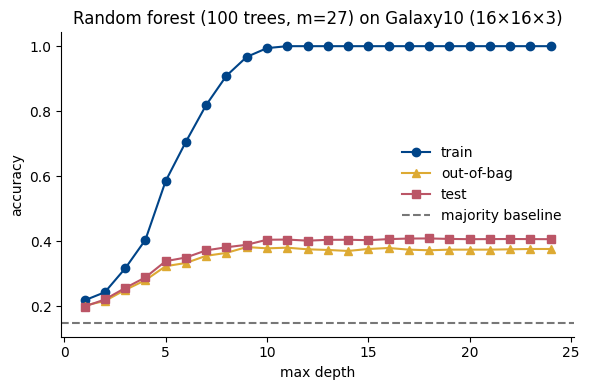

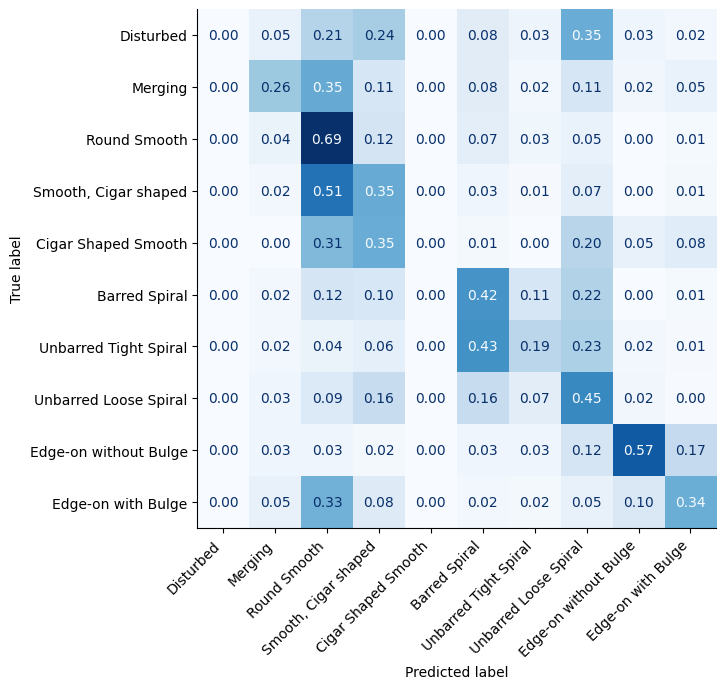

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

def path_values(tree, X, D):
    """Prediction of every sample when the tree is cut off at depth d = 0..D.
    A sample stays at its leaf once it reaches one. Shape (n_samples, D+1)."""
    out = np.empty((len(X), D + 1))
    for i, x in enumerate(np.asarray(X, float)):
        node = tree.root_
        for d in range(D + 1):
            out[i, d] = node.value
            if node.feature is not None:
                node = node.left if x[node.feature] <= node.threshold else node.right
    return out

# --- fit one fully grown forest ---
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, rng=np.random.default_rng(SEED)).fit(X_tr, y_tr)
print(f"fit time {time.time() - t0:.0f}s, m = {rf.max_features} features per split")

D = max(t.depth() for t in rf.trees_)
P_tr = np.stack([path_values(t, X_tr, D) for t in rf.trees_])     # (trees, n_train, D+1)
P_te = np.stack([path_values(t, X_test, D) for t in rf.trees_])   # (trees, n_test,  D+1)

K = len(classes)
oob_mask = np.zeros((len(rf.trees_), len(y_tr)), bool)            # True where tree k did NOT see row i
for k, oob in enumerate(rf.oob_):
    oob_mask[k, oob] = True

def vote(P, mask=None):
    """Majority vote over trees. P: (trees, n) labels. Optionally count only masked votes."""
    onehot = np.eye(K)[P.astype(int)]                             # (trees, n, K)
    if mask is not None:
        onehot = onehot * mask[:, :, None]
    tally = onehot.sum(axis=0)
    return tally.argmax(axis=1), tally.sum(axis=1) > 0

def acc(P, y, mask=None):
    pred, seen = vote(P, mask)
    return np.mean(pred[seen] == y[seen])

depths  = range(1, D + 1)
rf_tr   = [acc(P_tr[:, :, d], y_tr) for d in depths]
rf_oob  = [acc(P_tr[:, :, d], y_tr, oob_mask) for d in depths]
rf_te   = [acc(P_te[:, :, d], test_labels) for d in depths]

# --- plot 1: accuracy vs depth ---
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(depths, rf_tr,  "o-", color=BLUE,   label="train")
ax.plot(depths, rf_oob, "^-", color=YELLOW, label="out-of-bag")
ax.plot(depths, rf_te,  "s-", color=RED,    label="test")
ax.axhline(counts.max() / counts.sum(), ls="--", color=GREY, label="majority baseline")
ax.set_xlabel("max depth"); ax.set_ylabel("accuracy"); ax.legend(frameon=False)
ax.set_title(f"Random forest ({len(rf.trees_)} trees, m={rf.max_features}) on Galaxy10 (16×16×3)")
fig.tight_layout(); fig.savefig("rf_acc_vs_depth.pdf")

# --- plot 2: confusion matrix at the depth with best OOB accuracy ---
best_d = depths[int(np.argmax(rf_oob))]
y_pred, _ = vote(P_te[:, :, best_d])
print(f"depth {best_d}: test acc {np.mean(y_pred == test_labels):.3f}, "
      f"balanced acc {balanced_accuracy_score(test_labels, y_pred):.3f}")

cm = confusion_matrix(test_labels, y_pred, labels=classes, normalize="true")
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout(); fig.savefig("rf_confusion.pdf")